# US30 - Find the Best fitting curve

## 1. Requirements Engineering

### 1.1. User Story Description

As a Product Owner, I want to obtain the best-fitting curve for the previous sample, and see it graphically.

### 1.2. Acceptance Criteria

* **AC01**: The fitted curve should align with the reference function obtained from the theoretical analysis of the procedure’s complexity.
* **AC02**: Programming Language: Python
* **AC03**: Development environment: Jupyter Notebook
* **AC04**: Work delivery format: A single Jupyter Notebook file, containing all the work carried out for all US.
* **AC05**: Documented in Markdown format, for each US, you must present: Detailed description of the objectives and theoretical concepts on
     which the answers were based. Thorough analysis and interpretation of the obtained results, extrapolated to the PI topic.

### 1.3. Input and Output data

**Input Data:**

- CSV file with results from US29 regarding US13
- CSV file with results from US29 regarding US14

**Output Data:**

- Best fitting curve graph for US13 results
- Correlation Coefficient ($r^2$) of US13 results
- Residual Sum of Squares (RSS) of US13 results
- Best fitting curve graph for US14 results
- Correlation Coefficient ($r^2$) of US14 results
- Residual Sum of Squares (RSS) of US14 results


## 2. Objectives

This user story has the objective of gathering the results of US29 from two separate files and create a graph with the values given in the files. Then find the best fitting curve using diverse functions such as Linear function, Quadratic function and Cubic function, among others.
By obtaining all curves, the correlation coefficient ($r^2$) is calculated to determine the best fitting curve, and the curve with the highest $r^2$ is displayed and given the title of "best fitting curve".

## 3. Theoretical Concepts

The theoretical concepts used in this user story are the ones from the contents of Chapter 6 of MATCP - Simple Linear Regression

Regression model:

$$E(Y|x) = \beta_0 + \beta_1x$$

where:

- Y - Time
- $x$ - Number of edges
- $\beta_0$ and $\beta_1$ - Regression Coefficients
- E - Random component or Error

The Correlation Coefficient ($r^2$) is a measure of direction and degree in which two variables associate linearly.
It is calculated like this:

$$ r^2 = (\frac{S_{xy}}{\sqrt{S_{xx} \times S_{yy}}}) ^2 $$

where:

- $S_{xx} = \sum_{i=1}^{n} (x_i - \bar{x})^2 $
- $S_{yy} = \sum_{i=1}^{n} (y_i - \bar{y})^2 $
- $S_{xy} = \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$
- $\bar{x}$ - mean of all the $x$ values from the file
- $\bar{y}$ - mean of all the $y$ values from the file

Residual Sum of Squares:

$$ \text{SQE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = S_{yy} - \frac{S_{xy}^2}{S_{xx}} $$

## 4. Results Interpretation

For each user story (13 and 14) it is presented the following results:

- **Best fitting curve function**: The name of the function whose curve fits the input data best (eg. Linear $O(n)$, Quadratic $O(n^2)$, Cubic $O(n^3)$, Logarithmic $O(log(n))$) and its respective curve.
- **Correlation Coefficient $(r^2)$**: The highest $r^2$ value out of all the tested function, i.e, the closest to 1.
- **Residual Sum of Squares (RSS)**: The RSS value of the best fitting curve function.

=================================== US30 - Best Fitting Curve ===================================




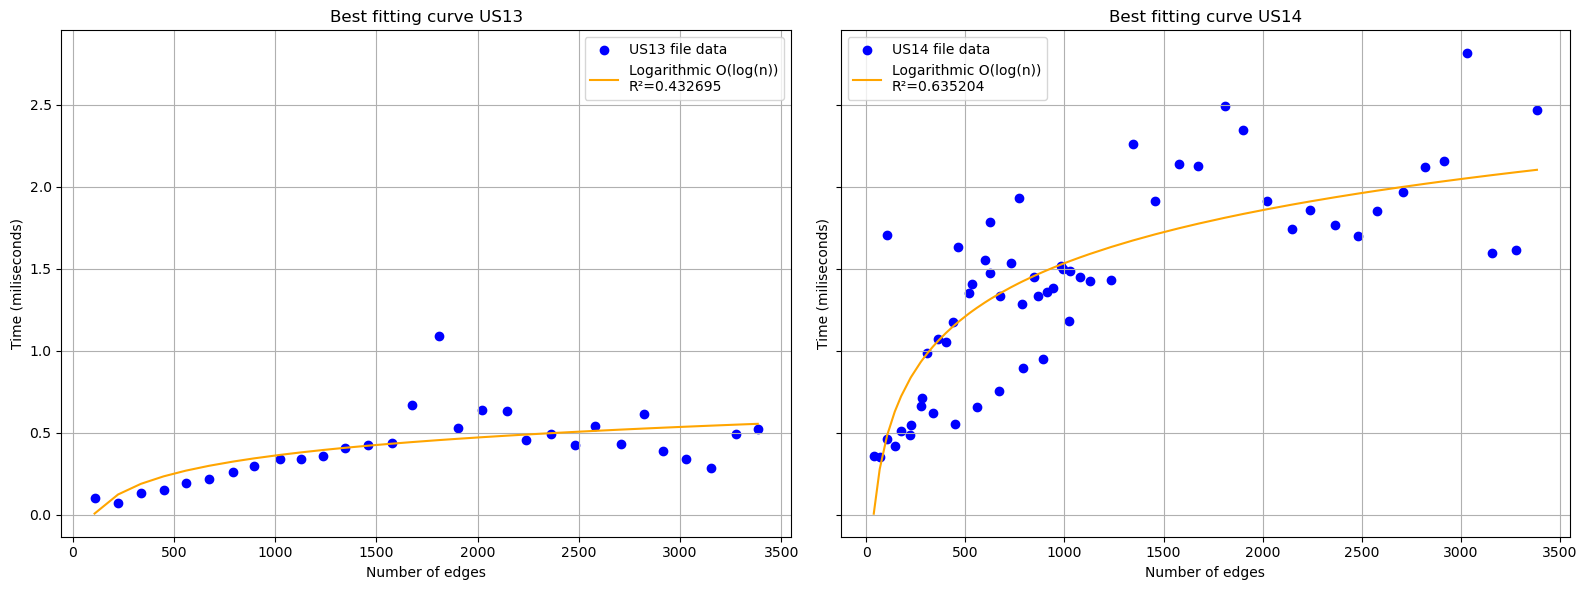

=========== US13 Curve ===========
Best fitting curve for US13 results: Logarithmic O(log(n))
R² = 0.432695
Residual Sum of Squares (RSS/SQE) = 0.700452



=========== US14 Curve ===========
Best fitting curve for US14 results: Logarithmic O(log(n))
R² = 0.635204
Residual Sum of Squares (RSS/SQE) = 7.704038


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

data13 = pd.read_csv("us13_results_us30.csv", sep=";", decimal=",")
data14 = pd.read_csv("us14_results_us30.csv", sep=";", decimal=",")

group13 = data13.groupby("size")["time"].mean().reset_index()
x13 = group13["size"].values
y13 = group13["time"].values

group14 = data14.groupby("size")["time"].mean().reset_index()
x14 = group14["size"].values
y14 = group14["time"].values

def bestFit(x, y):
    functions = {"Linear O(n)": x,
                 f"Quadratic O(n^2)": x ** 2,
                 f"Cubic O(n^3)": x ** 3,
                 "Logarithmic O(log(n))": np.log(x)}

    bestR2 = -1
    bestFit = None
    function = ""
    bestSQE = 0
    
    for (name, func) in functions.items():
        meanX = np.mean(func)
        meanY = np.mean(y)
        Sxx = 0
        Sxy = 0
        Syy = 0
        
        for index in range(len(x)):
            Sxx += (func[index] - meanX) ** 2
        for valueY in y:
            Syy += (valueY - meanY) ** 2
        for index in range(len(x)):
            Sxy += (func[index] - meanX) * (y[index] - meanY)
        
        r2 = (Sxy / math.sqrt(Sxx * Syy)) ** 2
        beta1 = Sxy / Sxx
        beta0 = meanY - (beta1 * meanX)
        fitY = beta0 + (beta1 * func)
        sqe = Syy - (Sxy ** 2 / Sxx)
        
        if r2 > bestR2:
            bestR2 = r2
            bestFit = fitY
            function = name
            bestSQE = sqe

    return bestR2, bestFit, function, bestSQE

r2_13, fit13, function13, sqe13 = bestFit(x13,y13)
r2_14, fit14, function14, sqe14 = bestFit(x14,y14)

fig, (us13, us14) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

us13.scatter(x13, y13, color="blue", label="US13 file data")
us13.plot(x13, fit13, color="orange", label=f'{function13}\nR²={r2_13:.6f}')
us13.set_xlabel("Number of edges")
us13.set_ylabel("Time (miliseconds)")
us13.set_title("Best fitting curve US13")
us13.grid(True)
us13.legend()

us14.scatter(x14, y14, color="blue", label="US14 file data")
us14.plot(x14, fit14, color="orange", label=f'{function14}\nR²={r2_14:.6f}')
us14.set_xlabel("Number of edges")
us14.set_ylabel("Time (miliseconds)")
us14.set_title("Best fitting curve US14")
us14.grid(True)
us14.legend()


plt.tight_layout()
plt.show()

print('=========== US13 Curve ===========')
print(f'Best fitting curve for US13 results: {function13}')
print(f'R² = {r2_13:.6f}')
print(f'Residual Sum of Squares (RSS/SQE) = {sqe13:.6f}')

print('\n\n')

print('=========== US14 Curve ===========')
print(f'Best fitting curve for US14 results: {function14}')
print(f'R² = {r2_14:.6f}')
print(f'Residual Sum of Squares (RSS/SQE) = {sqe14:.6f}')

## US31 – Revenue Prediction Based on Cargo Type (Simple Linear Regression)

### User Story Details
As a Player, using the same data file as in the previous Sprint  (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be applied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.

AC01: Programming Language: Python

AC02: Development environment: Jupyter Notebook

AC03: Work delivery format: A single Jupyter Notebook file, containing all the work carried out for all US.

AC04: Documented in Markdown format, for each US, you must present:
1. Detailed description of the objectives and theoretical concepts on which the answers were based.
2. Thorough analysis and interpretation of the obtained results, extrapolated to the PI topic.

---

### Objective
To identify the cargo type that most strongly correlates with the revenue of a specific railway station in a given year. Once identified, apply a simple linear regression model to that cargo type and estimate the revenue for January of the following year assuming a 10% increase in that cargo. The result must include a 95% prediction interval.

---

### Theoretical Concepts

This analysis is based on **Simple Linear Regression**, as covered in Chapter 6 of *Matemática Computacional*.

- The regression model has the form:
-
$$
E(Y \mid x) = \beta_0 + \beta_1 x
$$

where:
- \( Y \) is the revenue (dependent variable)
- \( X \) is the quantity of a cargo type (independent variable)
- \( $\beta_0$ \), \( $\beta_1$ \) are the regression coefficients
- \( E \) is the random error term


- The **Pearson correlation coefficient** \( r \) is used to measure the strength and direction of the linear relationship between each cargo type and the revenue.

- The **least squares method** is used to estimate the regression parameters \( $\beta_0$ \) and \( $\beta_1$ \), minimizing the sum of squared residuals:

$$
\text{SQE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = S_{yy} - \frac{S_{xy}^2}{S_{xx}}
$$


- A **95% prediction interval** is calculated for a future observation \( Y_0 \), using the following formula:

$$
\hat{y}_p \pm t_{1 - \frac{\alpha}{2}} \cdot s \cdot \sqrt{\frac{1}{n} + \frac{(x_p - \bar{x})^2}{S_{xx}}}
$$


where:
- \( s² \) is the estimated variance of residuals
- \( t_{1-\alpha/2} \) is the critical value from the t-distribution
- $$
  S_{xx} = \sum_{i=1}^{n} (x_i - \bar{x})^2
  $$

---

### Results and Interpretation

- **Best cargo type**: `{best_cargo}`
- **Correlation coefficient**: `{correlations[best_cargo]:.4f}`
- **Regression equation**:
  `y = {beta0:.2f} + {beta1:.2f}x`

- **January prediction with 10% increase**:
    - Estimated revenue: `{y_hat:.2f}`
    - 95% prediction interval: [`{lower:.2f}`, `{upper:.2f}`]

---

### Interpretation in the PI context

- The correlation analysis reveals the cargo type with the highest absolute correlation coefficient, representing the strongest revenue predictor. This relationship suggests either direct revenue impact or shared market influences. The linear regression model quantifies this relationship: the slope (β₁) represents revenue increase per cargo unit, while the intercept (β₀) indicates baseline revenue.
  The forecasting component uses historical January data as baseline, applying a realistic 10% increase scenario. The 95% confidence interval accounts for both model uncertainty and natural variation, providing a practical range for business planning.

- **Business Implications:** The analysis supports strategic decisions by identifying which cargo type to prioritize for resource allocation and capacity planning. However, the single-variable linear model has limitations - real revenue patterns may be non-linear and influenced by multiple factors not captured in this analysis.

In [9]:
import pandas as pd
import numpy as np
from scipy import stats

#reads csv file
data = pd.read_csv('Stations_Data.csv', sep= ';')

#display available stations for user to choose from
availableStations = data['Station'].unique()
print(f'Available Stations:')
for i, station in enumerate(sorted(availableStations), 1):
    print(f'{i:2d}. {station}')

#display available years for user to choose from
availableYears = data['Year'].unique()
print(f'\nAvailable Years:')
for j, year, in enumerate(sorted(availableYears), 1):
    print(f'{j:2d}. {year}')

#user input
station = int(input('\nChoose a station from the list (enter the correspondant number): '))
year = int(input('Choose a year from the list (enter the correspondant number): '))

#display either error message or recap of user's choices
if not (1 <= station <= len(sorted(availableStations))) or not (1 <= year <= len(sorted(availableYears))):
    print('Invalid option.')
else: 
    chosenStation = sorted(availableStations)[station - 1]
    chosenYear = sorted(availableYears)[year - 1]
    print(f'\n\nYou have chosen station "{chosenStation}" in {chosenYear}.')

#organize the document info in a revenue column
columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle', 'Revenues']

#convert values to either string or NaN if they're not numeric by replacing comma decimal seperators with dots for proper numeric convertion
for col in columns:
    data[col] = pd.to_numeric(data[col].astype(str).str.replace(',', '.', regex=False), errors='coerce')

#filter data for chosen year and station 
filtered = data[(data['Station'] == chosenStation) & (data['Year'] == chosenYear)]

#definition of cargo types and revenue
cargoTypes = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']

#find correlations and best cargo
correlations = filtered[cargoTypes + ['Revenues']].corr()['Revenues'].drop('Revenues')
best_cargo = correlations.abs().idxmax()
correlation_value = correlations[best_cargo]

print(f'\n\nCargo with the best correlation and revenue: {best_cargo}.')
print(f'Correlation: {correlation_value:.4f}')

#linear regression through minimal squares
x = filtered[best_cargo].values
y = filtered['Revenues'].values
n = len(x)
x_mean = np.mean(x)
y_mean = np.mean(y)
Sxx = np.sum((x - x_mean)**2)
Sxy = np.sum((x - x_mean) * (y - y_mean))
beta1 = Sxy / Sxx
beta0 = y_mean - beta1 * x_mean

print(f'\nLinear regression equation for "{chosenStation}" in {chosenYear}: y = {beta0:.2f} + {beta1:.2f}x')

#forecast of revenue for january with +10%
x_jan = filtered.loc[filtered['Month'] == 1, best_cargo].mean()
xp = x_jan * 1.10
y_hat = beta0 + beta1 * xp

#calculation of error and precision range
y_pred = beta0 + beta1 * x
sqe = np.sum((y - y_pred)**2)
s2 = sqe / (n - 2)

#precision range of 95%
t_val = stats.t.ppf(0.975, df=n - 2)
margin_error = t_val * np.sqrt(s2 * (1 + 1/n + ((xp - x_mean)**2) / Sxx))
lower = y_hat - margin_error
upper = y_hat + margin_error

print(f'\nEstimated revenue for January {chosenYear + 1} (with +10% of {best_cargo}): {y_hat:.2f}€')
print(f'Precision range 95%: [{lower:.2f}, {upper:.2f}]')

# AUTOMATIC RESULTS INTERPRETATION
print("\n\n" + "="*60)
print("RESULTS INTERPRETATION")
print("="*60)

# Correlation strength analysis
def interpret_correlation(r):
    abs_r = abs(r)
    if abs_r >= 0.8:
        return "very strong", "excellent predictor"
    elif abs_r >= 0.6:
        return "strong", "good predictor"
    elif abs_r >= 0.4:
        return "moderate", "reasonable predictor"
    elif abs_r >= 0.2:
        return "weak", "poor predictor"
    else:
        return "very weak", "very poor predictor"

strength, predictor_quality = interpret_correlation(correlation_value)
r_squared = correlation_value**2

print(f"\n1. CORRELATION ANALYSIS:")
print(f"   • {best_cargo} shows a {strength} {'positive' if correlation_value > 0 else 'negative'} correlation with revenue")
print(f"   • Correlation coefficient: {correlation_value:.4f}")
print(f"   • R²: {r_squared:.3f} ({r_squared*100:.1f}% of revenue variation explained)")
print(f"   • Assessment: {best_cargo} is a {predictor_quality} of station revenue")

print(f"\n2. LINEAR REGRESSION MODEL:")
print(f"   • Equation: Revenue = {beta0:.2f} + {beta1:.2f} × {best_cargo}")
print(f"   • Base revenue (when {best_cargo} = 0): {beta0:.2f}€")
print(f"   • Revenue per unit of {best_cargo}: {beta1:.2f}€")
if beta1 > 0:
    print(f"   • Economic meaning: Each additional unit of {best_cargo} increases revenue by {beta1:.2f}€")
else:
    print(f"   • Economic meaning: Each additional unit of {best_cargo} decreases revenue by {abs(beta1):.2f}€")

print(f"\n3. JANUARY FORECAST ANALYSIS:")
print(f"   • Baseline January {best_cargo} volume: {x_jan:.2f} units")
print(f"   • Projected volume (+10%): {xp:.2f} units")
print(f"   • Expected revenue: {y_hat:.2f}€")
confidence_width = upper - lower
print(f"   • Confidence interval width: {confidence_width:.2f}€")
print(f"   • Uncertainty level: ±{(confidence_width/2/y_hat)*100:.1f}% of predicted value")

=================================== US31 - Statistical Analysis ===================================


Available Stations:
 1. Berlin
 2. Frankfurt
 3. Hamburg
 4. Hannover
 5. Stuttgart

Available Years:
 1. 2015
 2. 2016
 3. 2017
 4. 2018
 5. 2019
 6. 2020
 7. 2021
 8. 2022
 9. 2023
10. 2024



Choose a station from the list (enter the correspondant number):  1
Choose a year from the list (enter the correspondant number):  2




You have chosen station "Berlin" in 2016.


Cargo with the best correlation and revenue: Iron.
Correlation: 0.7335

Linear regression equation for "Berlin" in 2016: y = 3605.46 + 0.16x

Estimated revenue for January 2017 (with +10% of Iron): 4387.10€
Precision range 95%: [2644.68, 6129.51]


RESULTS INTERPRETATION

1. CORRELATION ANALYSIS:
   • Iron shows a strong positive correlation with revenue
   • Correlation coefficient: 0.7335
   • R²: 0.538 (53.8% of revenue variation explained)
   • Assessment: Iron is a good predictor of station revenue

2. LINEAR REGRESSION MODEL:
   • Equation: Revenue = 3605.46 + 0.16 × Iron
   • Base revenue (when Iron = 0): 3605.46€
   • Revenue per unit of Iron: 0.16€
   • Economic meaning: Each additional unit of Iron increases revenue by 0.16€

3. JANUARY FORECAST ANALYSIS:
   • Baseline January Iron volume: 4343.06 units
   • Projected volume (+10%): 4777.37 units
   • Expected revenue: 4387.10€
   • Confidence interval width: 3484.83€
   • Uncerta